# Model Notebook
### Emotion Classification – Base Models + Stacking Ensemble

**Prerequisites:** Run `notebooks/preprocess.ipynb` first to generate `datasets/processed/`.

**Flow:**
1. Load processed data & config
2. Base model A – **Naive Bayes** (TF-IDF + MultinomialNB)
3. Base model B – **SVM** (TF-IDF + LinearSVC w/ calibration)
4. Base model C – **XGBoost** (TF-IDF + XGBClassifier)
5. **Stacking Ensemble** (out-of-fold → Logistic Regression meta-learner)
6. All models saved to `models/`

## 1. Load Processed Data & Configuration

In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from sklearn.preprocessing import LabelEncoder

# ---- Load config written by preprocess.ipynb ----
PROCESSED_DIR = os.path.join("../datasets", "processed")
with open(os.path.join(PROCESSED_DIR, "config.json")) as f:
    cfg = json.load(f)

EMOTION_LABELS = cfg["EMOTION_LABELS"]
N_FOLDS        = cfg["N_FOLDS"]
SEED           = cfg["SEED"]
K              = cfg["K"]
MODELS_DIR     = cfg["MODELS_DIR"]

os.makedirs(MODELS_DIR, exist_ok=True)

# ---- Load arrays ----
X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"), allow_pickle=True)
X_test  = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"),  allow_pickle=True)
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))
y_test  = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))
classes = np.load(os.path.join(PROCESSED_DIR, "label_encoder_classes.npy"), allow_pickle=True)

le = LabelEncoder()
le.classes_ = classes

print(f"Train: {len(X_train):,}  |  Test: {len(X_test):,}")
print(f"Classes ({K}):", list(le.classes_))
print(f"Emotion labels: {EMOTION_LABELS}")
print(f"N_FOLDS={N_FOLDS}  SEED={SEED}  MODELS_DIR='{MODELS_DIR}'")

Train: 1,670  |  Test: 418
Classes (5): [np.str_('anger'), np.str_('fear'), np.str_('none'), np.str_('sadness'), np.str_('unclear')]
Emotion labels: ['anger', 'fear', 'none', 'sadness', 'unclear']
N_FOLDS=5  SEED=42  MODELS_DIR='models'


## Helper – Confusion Matrix Plotter

In [2]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score
)

def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix", figsize=(8, 6)):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(K)))
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    plt.colorbar(im, ax=ax)
    ax.set(xticks=range(K), yticks=range(K),
           xticklabels=le.classes_, yticklabels=le.classes_,
           xlabel="Predicted label", ylabel="True label",
           title=title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    thresh = cm.max() / 2.0
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cm[i, j]}",
                    ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    plt.show()


def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"=== {name} ===")
    print(f"Accuracy : {acc:.4f}")
    print(f"F1-macro : {f1:.4f}")
    print()
    print(classification_report(y_true, y_pred,
                                 target_names=le.classes_,
                                 zero_division=0))
    plot_confusion_matrix(y_true, y_pred, title=f"Confusion Matrix – {name}")

print("Helper functions ready.")

Helper functions ready.


## Data Exploration & Word Clouds

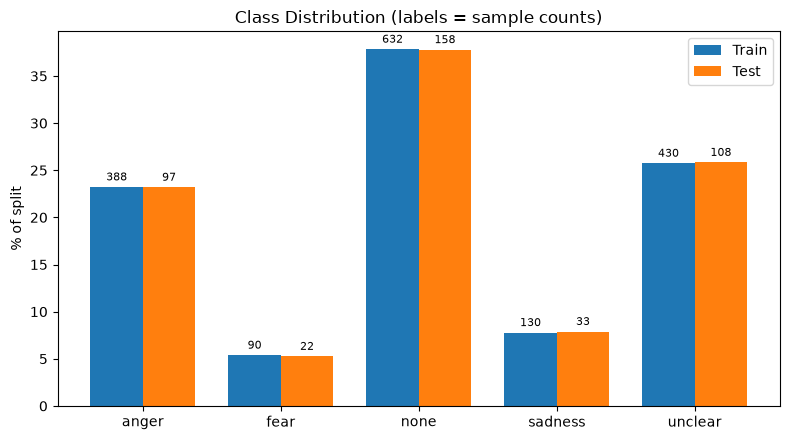

In [3]:
import os
import pandas as pd
from collections import Counter
from wordcloud import WordCloud, STOPWORDS

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")

CLASS_NAMES = [str(c) for c in le.classes_]
texts_train = [str(t) for t in X_train]
texts_test  = [str(t) for t in X_test]

# Add your own stop-words here (e.g. Indonesian ones) if the clouds are dominated by filler words
EXTRA_STOPWORDS = set()
STOP = set(STOPWORDS) | EXTRA_STOPWORDS

# ---- Class distribution (train vs test) ----
train_counts = np.bincount(y_train, minlength=K)
test_counts  = np.bincount(y_test,  minlength=K)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(K); w = 0.38
b1 = ax.bar(x - w/2, train_counts / train_counts.sum() * 100, w, label="Train")
b2 = ax.bar(x + w/2, test_counts  / test_counts.sum()  * 100, w, label="Test")
for bars, cnt in ((b1, train_counts), (b2, test_counts)):
    for rect, c in zip(bars, cnt):
        ax.text(rect.get_x() + rect.get_width()/2, rect.get_height() + 0.4, str(c),
                ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES)
ax.set_ylabel("% of split"); ax.set_title("Class Distribution (labels = sample counts)")
ax.legend(); plt.tight_layout(); save_fig("class_distribution"); plt.show()

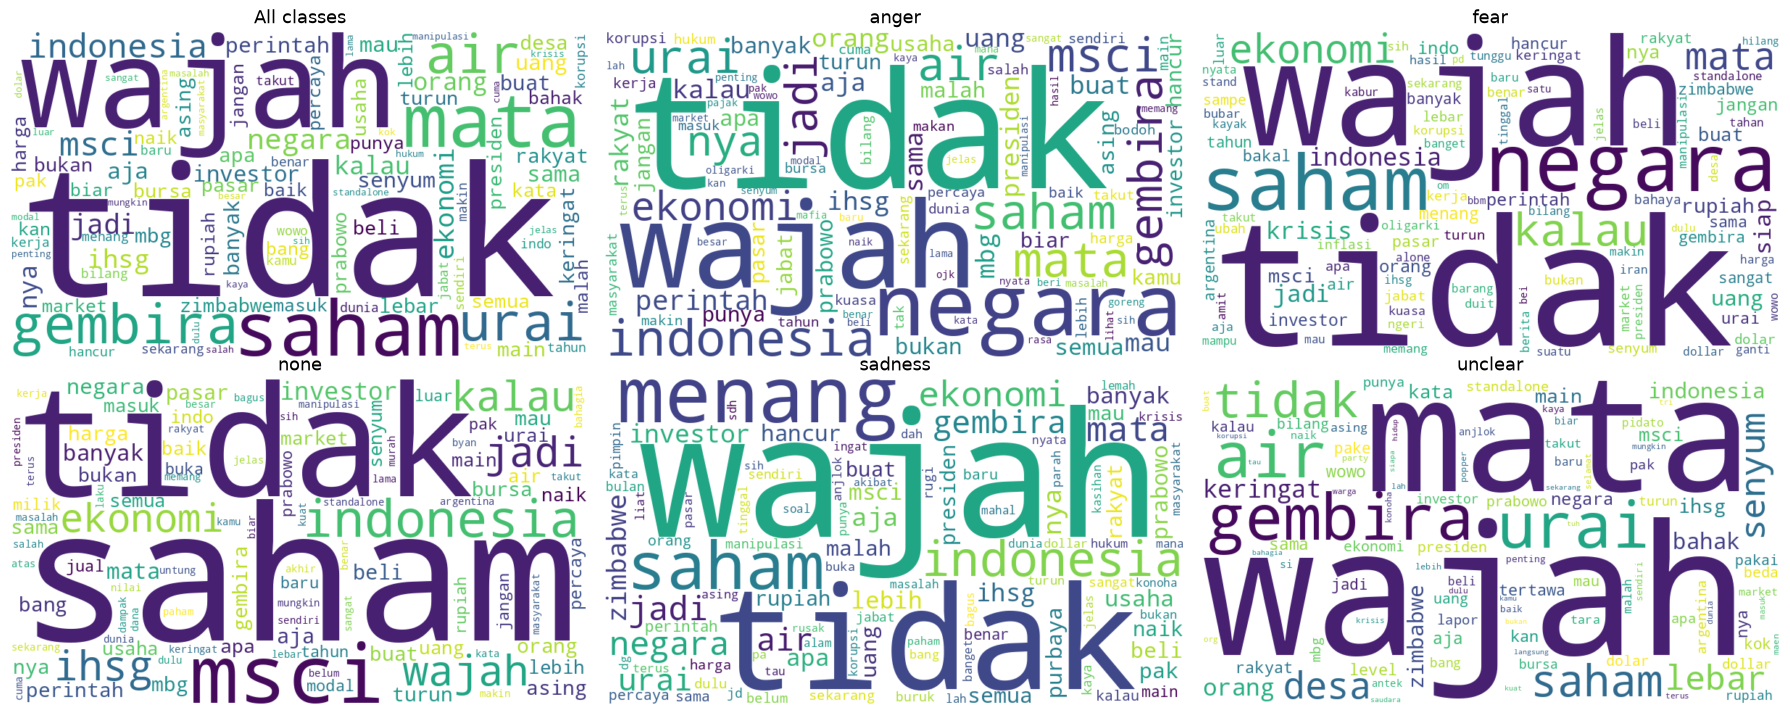

In [5]:
# ---- Word cloud per class + overall ----
def make_cloud(text):
    if not text.strip():
        return None
    return WordCloud(width=800, height=450, background_color="white",
                     stopwords=STOP, collocations=False, max_words=100,
                     random_state=SEED).generate(text)

panels = [("All classes", " ".join(texts_train))] + [
    (name, " ".join(t for t, y in zip(texts_train, y_train) if y == i))
    for i, name in enumerate(CLASS_NAMES)
]

ncols = 3
nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.6 * nrows))
for ax, (title, text) in zip(axes.ravel(), panels):
    wc = make_cloud(text)
    if wc is not None:
        ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title, fontsize=13); ax.axis("off")
for ax in axes.ravel()[len(panels):]:
    ax.axis("off")
plt.tight_layout(); save_fig("wordclouds_per_class"); plt.show()

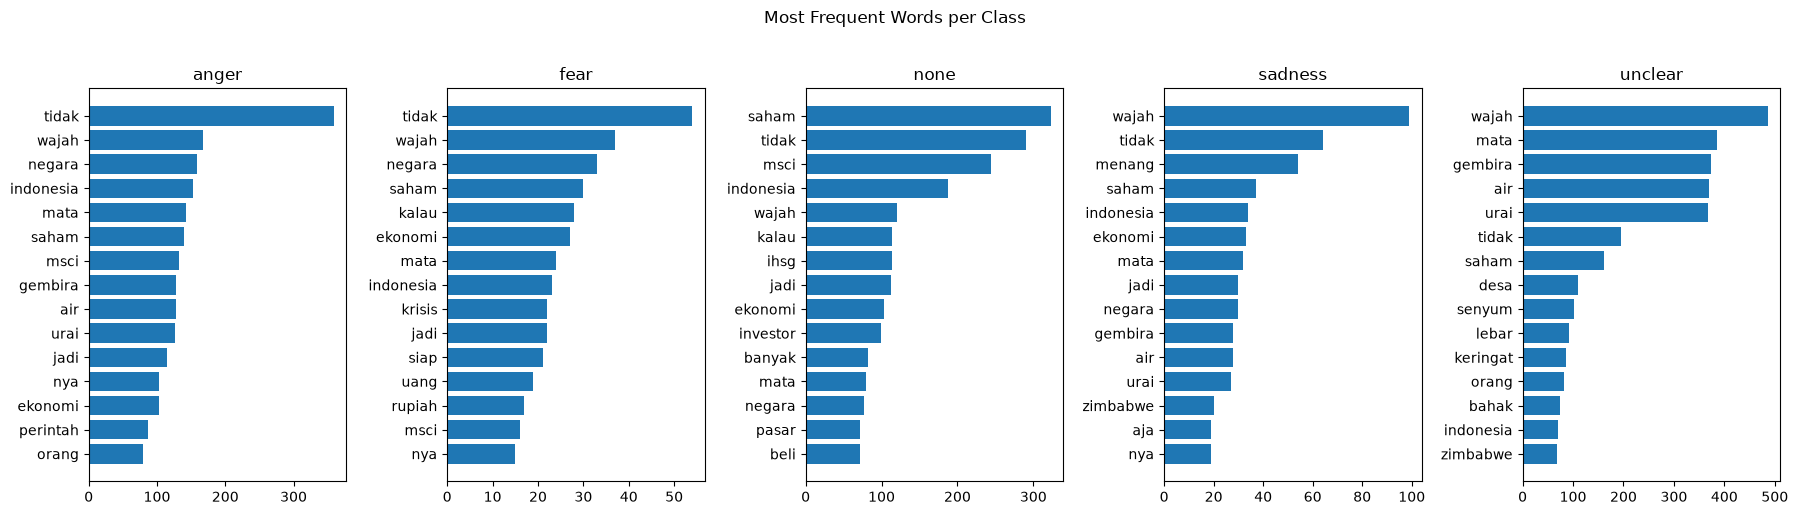

In [6]:
# ---- Top-15 most frequent words per class ----
TOP_N = 15
fig, axes = plt.subplots(1, K, figsize=(3.6 * K, 5), sharex=False)
for i, (ax, name) in enumerate(zip(np.atleast_1d(axes), CLASS_NAMES)):
    words = " ".join(t for t, y in zip(texts_train, y_train) if y == i).lower().split()
    cnt = Counter(w for w in words if w not in STOP and len(w) > 2).most_common(TOP_N)
    if cnt:
        labels, vals = zip(*cnt)
        ax.barh(labels[::-1], vals[::-1])
    ax.set_title(name)
plt.suptitle("Most Frequent Words per Class", y=1.02)
plt.tight_layout(); save_fig("top_words_per_class"); plt.show()

## 2. Base Model A – Naive Bayes

Naive Bayes model saved to 'models/naive_bayes.pkl'
=== Naive Bayes ===
Accuracy : 0.5909
F1-macro : 0.4105

              precision    recall  f1-score   support

       anger       0.63      0.33      0.43        97
        fear       0.00      0.00      0.00        22
        none       0.54      0.77      0.64       158
     sadness       1.00      0.15      0.26        33
     unclear       0.65      0.81      0.72       108

    accuracy                           0.59       418
   macro avg       0.56      0.41      0.41       418
weighted avg       0.60      0.59      0.55       418



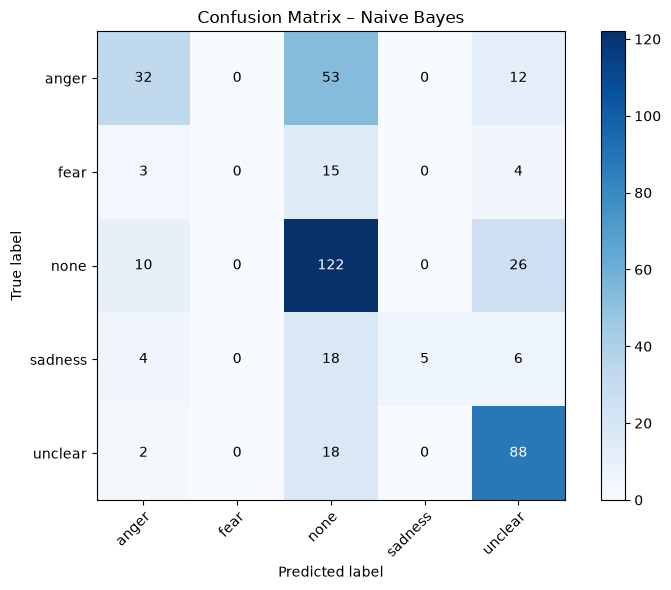

In [11]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

def make_nb():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf",   MultinomialNB(alpha=0.5)),
    ])

nb_model = make_nb()
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test)

# Save
nb_path = os.path.join(MODELS_DIR, "naive_bayes.pkl")
joblib.dump(nb_model, nb_path)
print(f"Naive Bayes model saved to '{nb_path}'")

evaluate("Naive Bayes", y_test, y_pred_nb)

## 3. Base Model B – SVM

SVM model saved to 'models/svm.pkl'
=== SVM ===
Accuracy : 0.6124
F1-macro : 0.5115

              precision    recall  f1-score   support

       anger       0.53      0.51      0.52        97
        fear       0.38      0.14      0.20        22
        none       0.61      0.66      0.63       158
     sadness       0.79      0.33      0.47        33
     unclear       0.67      0.81      0.74       108

    accuracy                           0.61       418
   macro avg       0.59      0.49      0.51       418
weighted avg       0.61      0.61      0.60       418



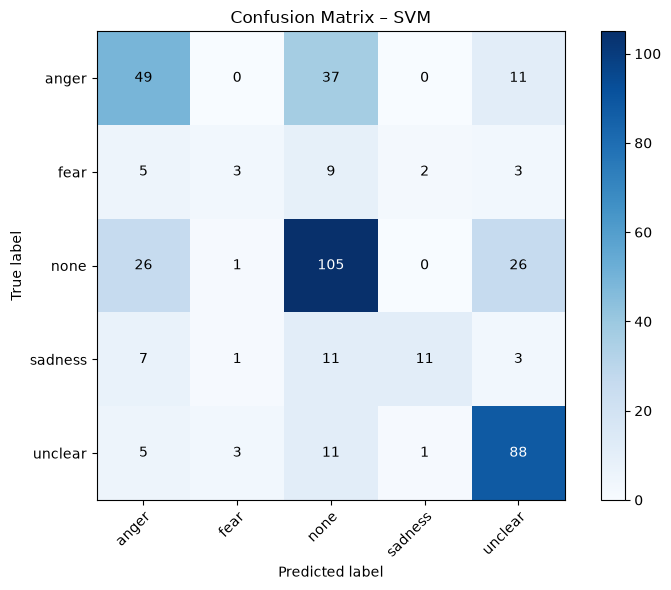

In [12]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

def make_svm():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf",   CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3)),
    ])

svm_model = make_svm()
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

# Save
svm_path = os.path.join(MODELS_DIR, "svm.pkl")
joblib.dump(svm_model, svm_path)
print(f"SVM model saved to '{svm_path}'")

evaluate("SVM", y_test, y_pred_svm)

## 4. Base Model C – XGBoost

/mnt/c/College_Computer_Science/Sem 7/ML/Tugas_3/.venv/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [20:12:35] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost model saved to 'models/xgboost.pkl'
=== XGBoost ===
Accuracy : 0.6053
F1-macro : 0.4936

              precision    recall  f1-score   support

       anger       0.57      0.48      0.52        97
        fear       0.20      0.09      0.12        22
        none       0.61      0.70      0.65       158
     sadness       0.57      0.39      0.46        33
     unclear       0.67      0.75      0.71       108

    accuracy                           0.61       418
   macro avg       0.52      0.48      0.49       418
weighted avg       0.59      0.61      0.59       418



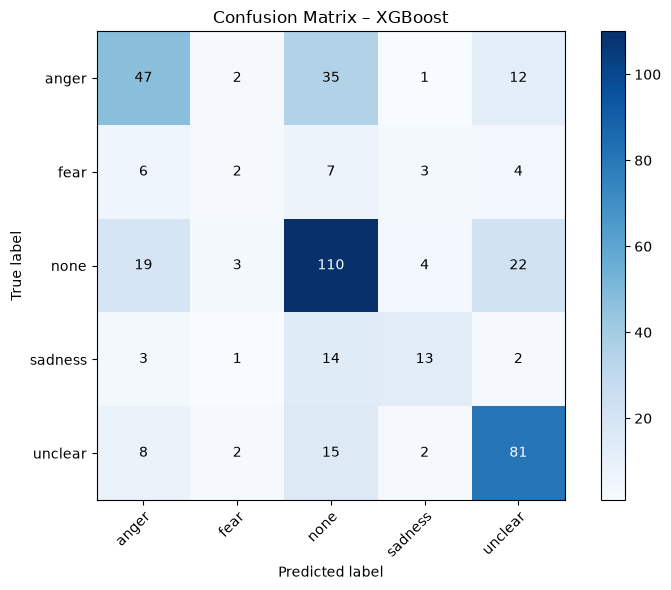

In [13]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from scipy.sparse import issparse

# Wrap XGBoost in a pipeline-compatible estimator
# XGBClassifier needs numeric labels starting at 0
def make_xgb():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf",   XGBClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            use_label_encoder=False,
            eval_metric="mlogloss",
            random_state=SEED,
            n_jobs=-1,
        )),
    ])

xgb_model = make_xgb()
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

# Save
xgb_path = os.path.join(MODELS_DIR, "xgboost.pkl")
joblib.dump(xgb_model, xgb_path)
print(f"XGBoost model saved to '{xgb_path}'")

evaluate("XGBoost", y_test, y_pred_xgb)

## 5. Stacking Ensemble

**Strategy:** Out-of-fold (OOF) predictions from the three base models become
features for a Logistic Regression meta-learner.  This avoids data leakage
because each training fold's predictions are made by a model that never saw
those samples during training.

```
              [NB proba] [SVM proba] [XGB proba]
                         ↓
              Logistic Regression (meta-learner)
                         ↓
                  Emotion prediction
```

### 5.1 Generate Out-of-Fold Predictions

In [14]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
n_train = len(X_train)

oof = {
    "nb":  np.zeros((n_train, K)),
    "svm": np.zeros((n_train, K)),
    "xgb": np.zeros((n_train, K)),
}

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_train, y_train), 1):
    print(f"Fold {fold}/{N_FOLDS}")
    Xtr, Xva = X_train[tr_idx], X_train[va_idx]
    ytr = y_train[tr_idx]

    nb_f  = make_nb().fit(Xtr, ytr)
    svm_f = make_svm().fit(Xtr, ytr)
    xgb_f = make_xgb().fit(Xtr, ytr)

    oof["nb"][va_idx]  = nb_f.predict_proba(Xva)
    oof["svm"][va_idx] = svm_f.predict_proba(Xva)
    oof["xgb"][va_idx] = xgb_f.predict_proba(Xva)

print("OOF prediction complete.")

Fold 1/5


/mnt/c/College_Computer_Science/Sem 7/ML/Tugas_3/.venv/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [20:12:51] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 2/5


/mnt/c/College_Computer_Science/Sem 7/ML/Tugas_3/.venv/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [20:13:04] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 3/5


...

Fold 4/5


/mnt/c/College_Computer_Science/Sem 7/ML/Tugas_3/.venv/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [20:13:25] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 5/5


/mnt/c/College_Computer_Science/Sem 7/ML/Tugas_3/.venv/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [20:13:36] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


OOF prediction complete.


### 5.2 Train Meta-Learner

In [15]:
from sklearn.linear_model import LogisticRegression

meta_train = np.hstack([oof["nb"], oof["svm"], oof["xgb"]])

meta_learner = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED,
)
meta_learner.fit(meta_train, y_train)
print("Meta-learner (Logistic Regression) trained.")

Meta-learner (Logistic Regression) trained.


### 5.3 Evaluate Stacking Ensemble on Test Set

=== Stacking Ensemble (NB + SVM + XGBoost) ===
Accuracy : 0.5598
F1-macro : 0.4951

              precision    recall  f1-score   support

       anger       0.50      0.52      0.51        97
        fear       0.15      0.27      0.20        22
        none       0.66      0.52      0.58       158
     sadness       0.47      0.52      0.49        33
     unclear       0.67      0.73      0.70       108

    accuracy                           0.56       418
   macro avg       0.49      0.51      0.50       418
weighted avg       0.58      0.56      0.57       418



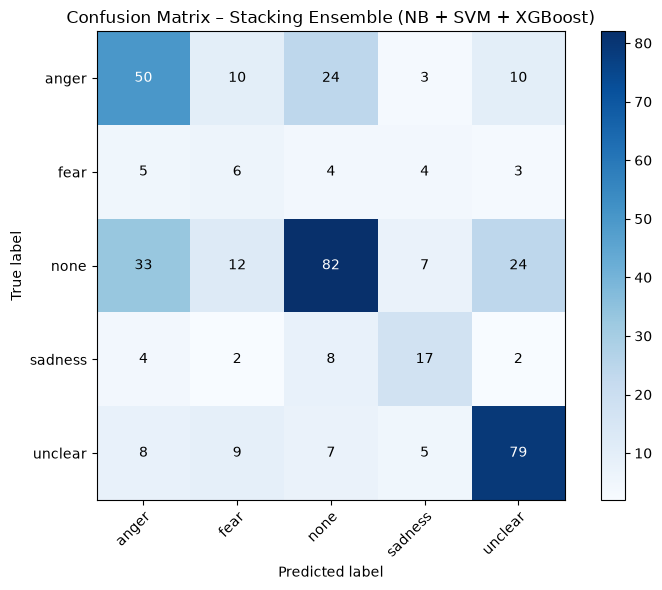

In [16]:
# Generate test-set probabilities from each base model (trained on full train set)
p_nb  = nb_model.predict_proba(X_test)
p_svm = svm_model.predict_proba(X_test)
p_xgb = xgb_model.predict_proba(X_test)

meta_test  = np.hstack([p_nb, p_svm, p_xgb])
y_pred_ens = meta_learner.predict(meta_test)

evaluate("Stacking Ensemble (NB + SVM + XGBoost)", y_test, y_pred_ens)

## 6. Save All Models

In [17]:
# Base models were already saved individually above.
# Save the meta-learner.
meta_path = os.path.join(MODELS_DIR, "meta_learner.pkl")
joblib.dump(meta_learner, meta_path)

# Save the label-encoder classes so inference code can reconstruct it
le_path = os.path.join(MODELS_DIR, "label_encoder_classes.npy")
np.save(le_path, le.classes_)

print("All models saved:")
for fname in ["naive_bayes.pkl", "svm.pkl", "xgboost.pkl",
              "meta_learner.pkl", "label_encoder_classes.npy"]:
    fpath = os.path.join(MODELS_DIR, fname)
    size  = os.path.getsize(fpath) / 1024
    print(f"  {fpath}  ({size:.1f} KB)")

All models saved:
  models/naive_bayes.pkl  (504.8 KB)
  models/svm.pkl  (703.6 KB)
  models/xgboost.pkl  (1535.4 KB)
  models/meta_learner.pkl  (1.5 KB)
  models/label_encoder_classes.npy  (0.3 KB)


## 7. Summary Comparison

In [18]:
import pandas as pd

results = []
for name, y_pred in [
    ("Naive Bayes", y_pred_nb),
    ("SVM",         y_pred_svm),
    ("XGBoost",     y_pred_xgb),
    ("Ensemble",    y_pred_ens),
]:
    results.append({
        "Model":    name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "F1-macro": round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4),
    })

summary = pd.DataFrame(results).set_index("Model")
print(summary.to_string())
summary

             Accuracy  F1-macro
Model                          
Naive Bayes    0.5909    0.4105
SVM            0.6124    0.5115
XGBoost        0.6053    0.4936
Ensemble       0.5598    0.4951


,Accuracy,F1-macro
Model,,
Naive Bayes,0.5909,0.4105
SVM,0.6124,0.5115
XGBoost,0.6053,0.4936
Ensemble,0.5598,0.4951


## 8. Output Analysis & Visualizations

Everything below uses the already-trained models and test-set predictions. Figures are also saved to `figures/`.

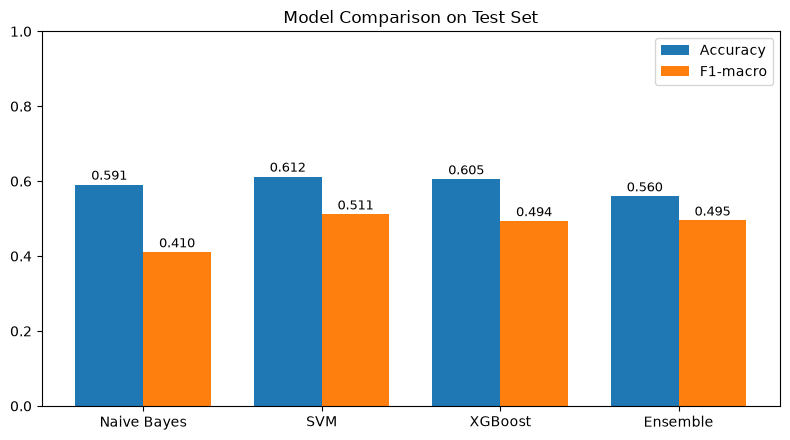

In [19]:
from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

preds = {
    "Naive Bayes": y_pred_nb,
    "SVM":         y_pred_svm,
    "XGBoost":     y_pred_xgb,
    "Ensemble":    y_pred_ens,
}
proba_ens = meta_learner.predict_proba(meta_test)
y_test_bin = label_binarize(y_test, classes=list(range(K)))

# ---- 8.1 Overall model comparison ----
acc = [accuracy_score(y_test, p) for p in preds.values()]
f1m = [f1_score(y_test, p, average="macro", zero_division=0) for p in preds.values()]

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(preds)); w = 0.38
r1 = ax.bar(x - w/2, acc, w, label="Accuracy")
r2 = ax.bar(x + w/2, f1m, w, label="F1-macro")
for r in list(r1) + list(r2):
    ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.005, f"{r.get_height():.3f}",
            ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(preds.keys()); ax.set_ylim(0, 1)
ax.set_title("Model Comparison on Test Set"); ax.legend()
plt.tight_layout(); save_fig("model_comparison"); plt.show()

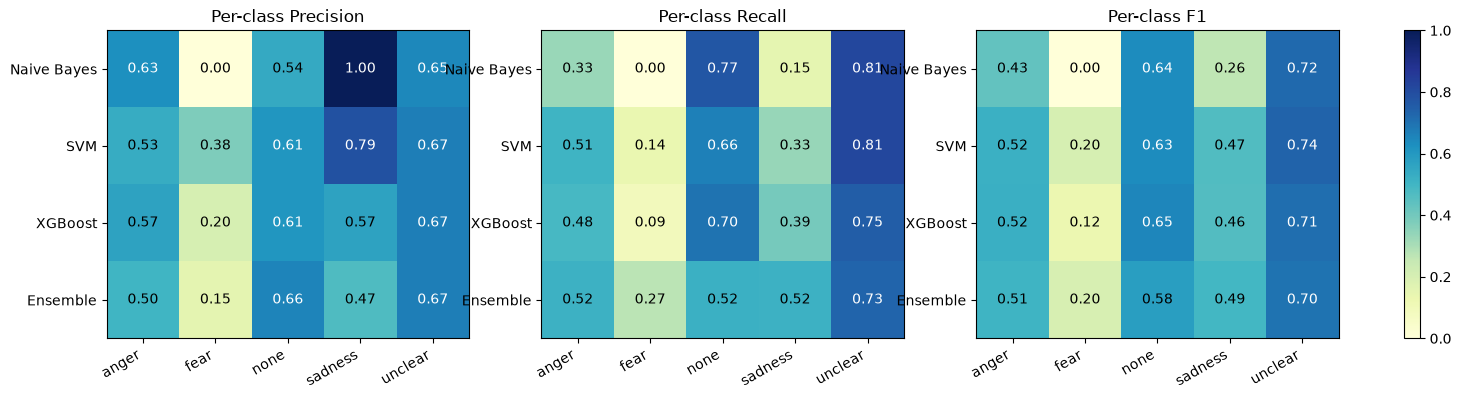

In [20]:
# ---- 8.2 Per-class F1 / precision / recall heatmaps ----
metrics = {"Precision": 0, "Recall": 1, "F1": 2}
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (mname, midx) in zip(axes, metrics.items()):
    mat = np.array([
        precision_recall_fscore_support(y_test, p, labels=list(range(K)), zero_division=0)[midx]
        for p in preds.values()
    ])
    im = ax.imshow(mat, vmin=0, vmax=1, cmap="YlGnBu", aspect="auto")
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(len(preds))); ax.set_yticklabels(preds.keys())
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center",
                    color="white" if mat[i, j] > 0.6 else "black")
    ax.set_title(f"Per-class {mname}")
plt.colorbar(im, ax=axes, fraction=0.015)
save_fig("per_class_metrics"); plt.show()

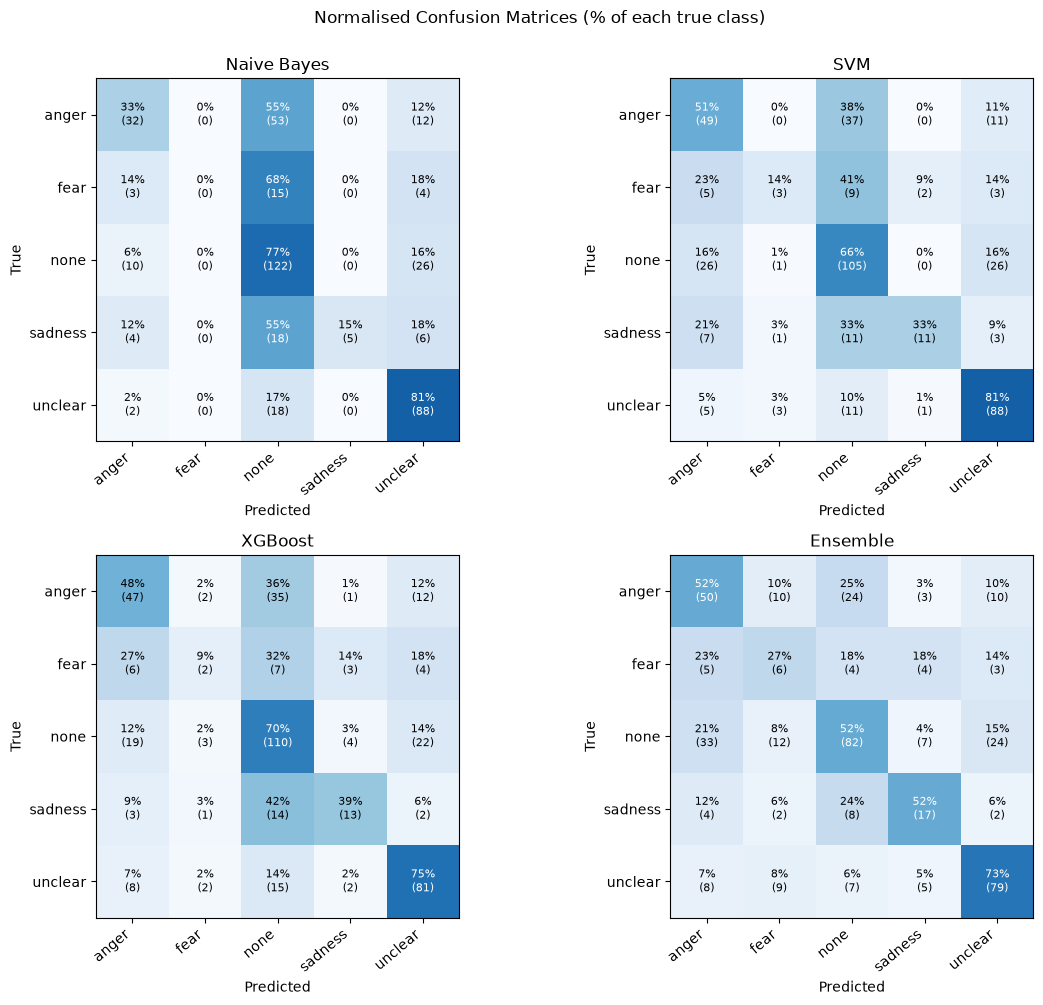

In [21]:
# ---- 8.3 Row-normalised confusion matrices (recall view) for all models ----
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, p) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, p, labels=list(range(K)))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_xticklabels(CLASS_NAMES, rotation=40, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.suptitle("Normalised Confusion Matrices (% of each true class)", y=1.00)
plt.tight_layout(); save_fig("confusion_matrices_normalised"); plt.show()

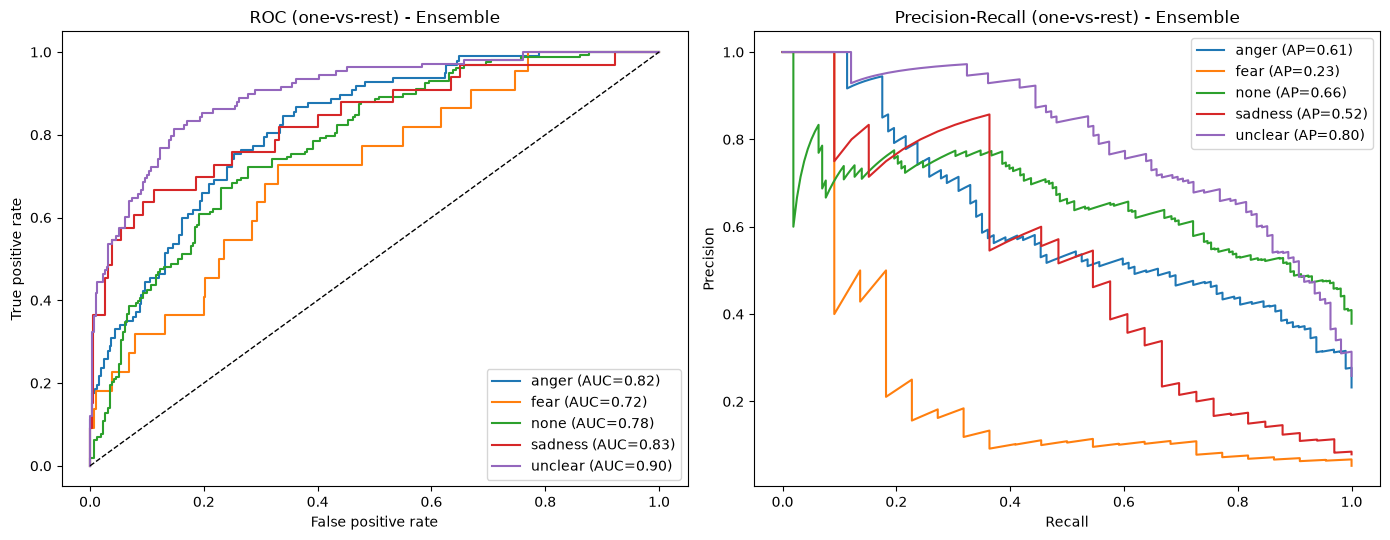

In [22]:
# ---- 8.4 ROC and Precision-Recall curves (one-vs-rest, Ensemble) ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba_ens[:, i])
    ax1.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.2f})")
    prec, rec, _ = precision_recall_curve(y_test_bin[:, i], proba_ens[:, i])
    ax2.plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test_bin[:, i], proba_ens[:, i]):.2f})")
ax1.plot([0, 1], [0, 1], "k--", lw=1)
ax1.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (one-vs-rest) - Ensemble")
ax2.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (one-vs-rest) - Ensemble")
ax1.legend(loc="lower right"); ax2.legend(loc="upper right")
plt.tight_layout(); save_fig("roc_pr_ensemble"); plt.show()

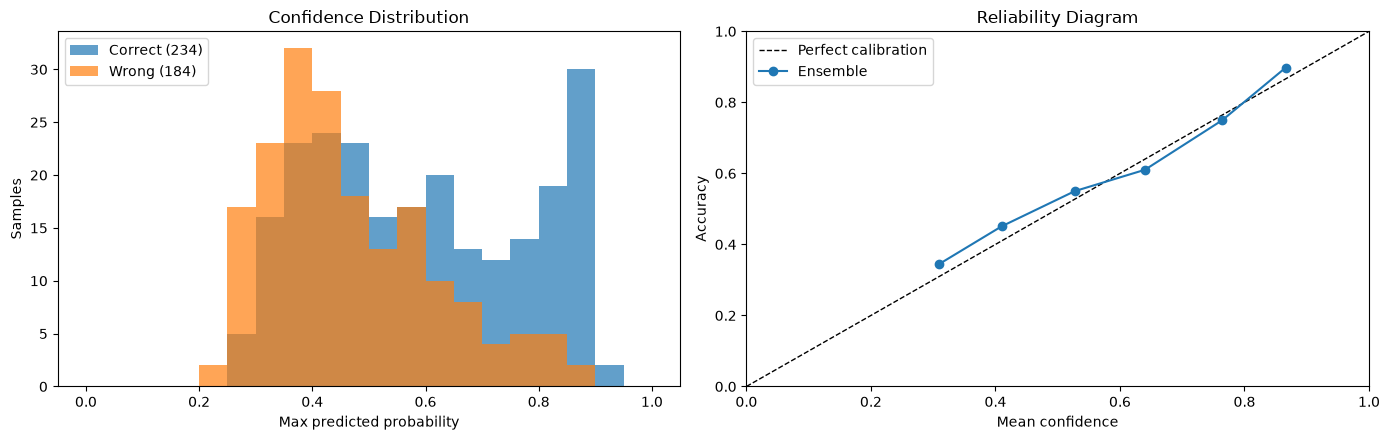

In [23]:
# ---- 8.5 Confidence: correct vs wrong predictions (Ensemble) ----
conf = proba_ens.max(axis=1)
correct = (y_pred_ens == y_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.linspace(0, 1, 21)
ax1.hist(conf[correct],  bins=bins, alpha=0.7, label=f"Correct ({correct.sum()})")
ax1.hist(conf[~correct], bins=bins, alpha=0.7, label=f"Wrong ({(~correct).sum()})")
ax1.set(xlabel="Max predicted probability", ylabel="Samples", title="Confidence Distribution")
ax1.legend()

# Reliability: accuracy per confidence bin
edges = np.linspace(conf.min(), conf.max(), 7)
idx = np.digitize(conf, edges[1:-1])
bin_acc  = [correct[idx == b].mean() if (idx == b).any() else np.nan for b in range(6)]
bin_conf = [conf[idx == b].mean()    if (idx == b).any() else np.nan for b in range(6)]
ax2.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax2.plot(bin_conf, bin_acc, "o-", label="Ensemble")
ax2.set(xlabel="Mean confidence", ylabel="Accuracy", title="Reliability Diagram", xlim=(0, 1), ylim=(0, 1))
ax2.legend()
plt.tight_layout(); save_fig("confidence_analysis"); plt.show()

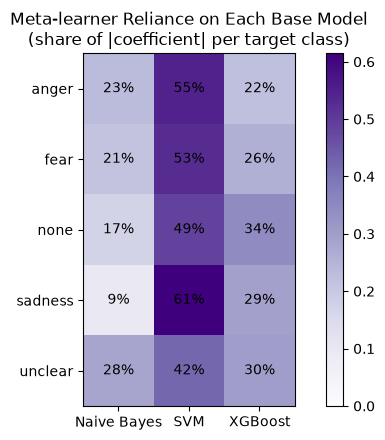

In [24]:
# ---- 8.6 Which base model does the meta-learner trust, per class? ----
# meta_learner.coef_ has shape (K, 3*K): [NB probs | SVM probs | XGB probs]
coef = meta_learner.coef_
base_names = ["Naive Bayes", "SVM", "XGBoost"]
weight = np.array([[np.abs(coef[c, b*K:(b+1)*K]).sum() for b in range(3)] for c in range(K)])
weight = weight / weight.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(weight, cmap="Purples", vmin=0, vmax=weight.max())
ax.set_xticks(range(3)); ax.set_xticklabels(base_names)
ax.set_yticks(range(K)); ax.set_yticklabels(CLASS_NAMES)
for i in range(K):
    for j in range(3):
        ax.text(j, i, f"{weight[i, j]:.0%}", ha="center", va="center")
ax.set_title("Meta-learner Reliance on Each Base Model\n(share of |coefficient| per target class)")
plt.colorbar(im, ax=ax); plt.tight_layout(); save_fig("meta_learner_weights"); plt.show()

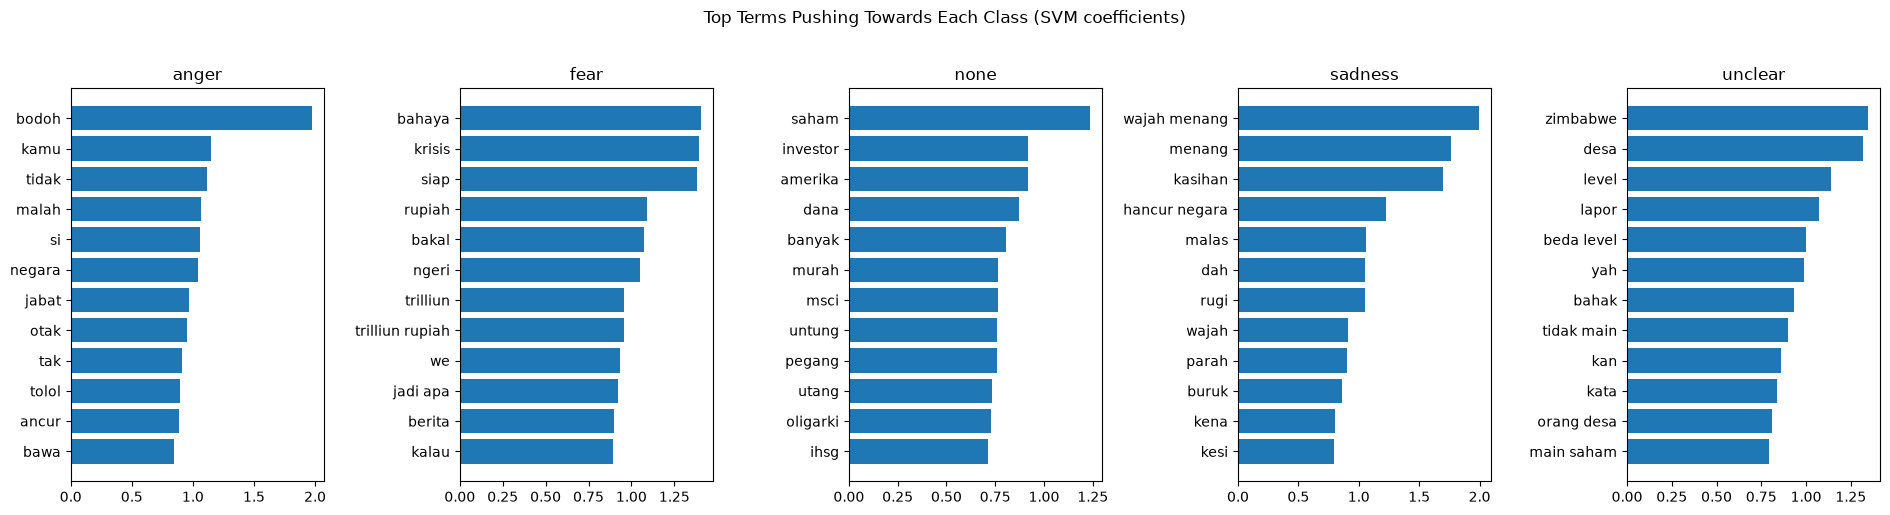

In [25]:
# ---- 8.7 Most discriminative terms per class (from the linear SVM) ----
tfidf = svm_model.named_steps["tfidf"]
vocab = np.array(tfidf.get_feature_names_out())
cal = svm_model.named_steps["clf"]
coefs = []
for cc in cal.calibrated_classifiers_:
    est = getattr(cc, "estimator", None)
    if est is None:
        est = cc.base_estimator
    coefs.append(est.coef_)
svm_coef = np.mean(coefs, axis=0)           # (K, n_features)

TOP = 12
fig, axes = plt.subplots(1, K, figsize=(3.8 * K, 5))
for i, ax in enumerate(np.atleast_1d(axes)):
    top = np.argsort(svm_coef[i])[-TOP:]
    ax.barh(vocab[top], svm_coef[i][top])
    ax.set_title(CLASS_NAMES[i])
plt.suptitle("Top Terms Pushing Towards Each Class (SVM coefficients)", y=1.02)
plt.tight_layout(); save_fig("svm_top_terms"); plt.show()

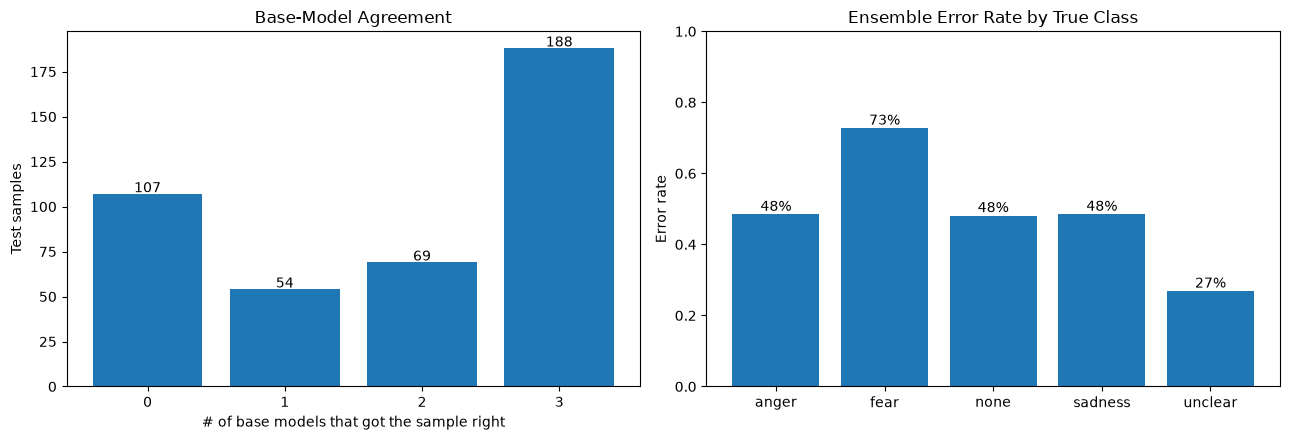

,text,true,pred,confidence
115,mbg sabotase alam sabotase karhutla ihsg serang sadar negara sedang perang wajah menang satu teguh,fear,sadness,0.877
226,orang desa engga main saham kan orang desa konoha,none,unclear,0.876
328,berdikari standalone wajah senyum air mata,sadness,unclear,0.826
170,ganti pak pur harap ihsg naik malah terjun bebas wajah gembira urai air mata bodoh jabat jangan sampe bikin indonesi...,fear,sadness,0.826
350,lewat krisis kok belum rame berita demo,none,fear,0.824
399,saham bayan manipulasi isam wajah gembira urai air mata,none,unclear,0.810
403,bangkrut rupiah koncet,none,fear,0.807
46,hina laku msci wajah gembira urai air mata ikut mau elite global,anger,unclear,0.795
162,otw rupiah lembar nominal trilliun,unclear,fear,0.790
303,mau ihsg smci bodo wajah senyum lebar keringat wajah senyum lebar keringat,none,unclear,0.775


In [26]:
# ---- 8.8 Model agreement & error analysis ----
base_correct = np.vstack([
    (y_pred_nb  == y_test),
    (y_pred_svm == y_test),
    (y_pred_xgb == y_test),
]).sum(axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
vals = np.bincount(base_correct, minlength=4)
ax1.bar(range(4), vals)
for i, v in enumerate(vals):
    ax1.text(i, v + 1, str(v), ha="center")
ax1.set_xticks(range(4)); ax1.set_xlabel("# of base models that got the sample right")
ax1.set_ylabel("Test samples"); ax1.set_title("Base-Model Agreement")

# Error rate per true class (Ensemble)
err_rate = [(y_pred_ens[y_test == i] != i).mean() for i in range(K)]
ax2.bar(CLASS_NAMES, err_rate)
for i, v in enumerate(err_rate):
    ax2.text(i, v + 0.01, f"{v:.0%}", ha="center")
ax2.set_ylim(0, 1); ax2.set_ylabel("Error rate"); ax2.set_title("Ensemble Error Rate by True Class")
plt.tight_layout(); save_fig("agreement_and_errors"); plt.show()

# Most confident mistakes -> worth reading manually (label noise? ambiguous text?)
err_df = pd.DataFrame({
    "text":       texts_test,
    "true":       [CLASS_NAMES[i] for i in y_test],
    "pred":       [CLASS_NAMES[i] for i in y_pred_ens],
    "confidence": conf.round(3),
})
err_df = err_df[err_df["true"] != err_df["pred"]].sort_values("confidence", ascending=False)
pd.set_option("display.max_colwidth", 120)
err_df.head(15)